# 04.1 Naive Bayes (experimento 1)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: resultados de validación cruzada de este modelo, para compararlos con los demás

Instrucciones:

- Validación: `GroupKFold(n_splits=5, shuffle=True, random_state=SEED)` agrupando por `animal_id_intake`. Es la misma en todos los notebooks.
- Hiperparámetros: salen de la búsqueda con Optuna del mismo modelo (carpeta `04-hyperparameter-optimization-experiment-1`), con `load_best(...)` y los nombres `nb_clf`. Si las variables o los datos cambian, hay que repetir esa búsqueda.
- Preprocesamiento: `build_preprocessor(columns=...)` dentro de un `Pipeline`, para que se ajuste en cada fold.
- Métricas: clasificación con macro-F1 y reporte por clase. Regresión con MAE en días (`np.expm1`) y R² en log.
- Resultados por fold: mostrar también el resultado de cada fold, como en `04.1-svm.ipynb` (sección 4).
- No usar `test`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, FEATURES, build_preprocessor
from tuning import load_best

data = pd.read_csv("../../data/processed/dev_features.csv")
groups = data["animal_id_intake"]
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

c:\Users\MAURO\Desktop\GIT\mucsi-ml-animal-shelter-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import cross_val_predict
from sklearn.naive_bayes import MultinomialNB

## Inputs

- `AVAILABLE`: las 22 variables de `dev_features.csv`.
- `FEATURES_EXP1_CLF` y `FEATURES_EXP1_REG`: variables del experimento 1 para este modelo, en clasificación y en regresión. Variables categóricas y binarias. Solo clasifica.

In [3]:
AVAILABLE = FEATURES
FEATURES_EXP1_CLF = CAT_LOW + CAT_HIGH + BINARY

print("El experimento 1 usa estas variables:")
print("Clasificación:", FEATURES_EXP1_CLF)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

El experimento 1 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious']


## Hiperparámetros

Salen de la búsqueda con Optuna del experimento 1. Si las variables o los datos cambiaron desde esa búsqueda, `load_best` se detiene y avisa que hay que repetirla.

In [4]:
## Hiperparámetros
# Salen de la búsqueda con Optuna del experimento 1.
params_clf = load_best("nb_clf", FEATURES_EXP1_CLF)

Ajustes cargados de nb_clf.json: {'alpha': 0.0074593432857265485}
(en la búsqueda: macro-F1 = 0.4432)


## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas.

macro-F1: 0.443  (siempre la clase más frecuente: 0.119)

                 precision    recall  f1-score   support

       Adoption       0.60      0.42      0.49     27073
     Euthanasia       0.73      0.57      0.64      4986
          Other       0.15      0.00      0.01       834
Return to Owner       0.46      0.75      0.57     11757
       Transfer       0.48      0.54      0.51     19031

       accuracy                           0.52     63681
      macro avg       0.48      0.46      0.44     63681
   weighted avg       0.54      0.52      0.52     63681



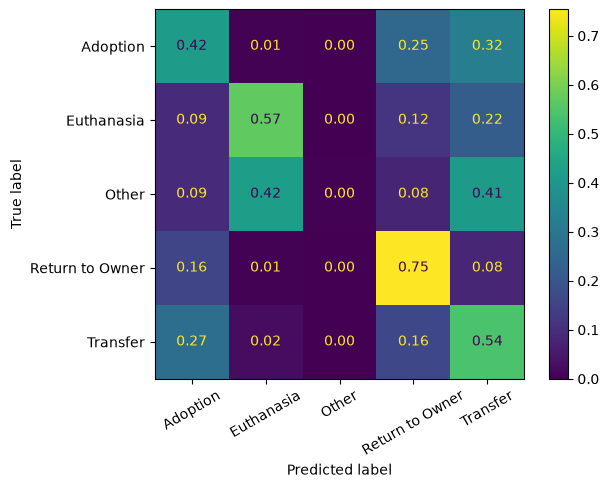

In [5]:
## 1. Clasificación
# Se evalúa con todos los datos. Cada fila se predice con un modelo que no la vio.
pipe_clf = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_CLF)), 
                     ("model", MultinomialNB(**params_clf))])
X_clf = data[FEATURES_EXP1_CLF]

pred_clf = cross_val_predict(pipe_clf, X_clf, y_clf, groups=groups, cv=cv, n_jobs=5)
base_clf = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_clf, y_clf, groups=groups, cv=cv)

print(f"macro-F1: {f1_score(y_clf, pred_clf, average='macro'):.3f}  (siempre la clase más frecuente: {f1_score(y_clf, base_clf, average='macro'):.3f})\n")
print(classification_report(y_clf, pred_clf))

ConfusionMatrixDisplay.from_predictions(y_clf, pred_clf, normalize="true", xticks_rotation=30, values_format=".2f")
plt.show()


## 2. Resultados

In [6]:
## 2. Resultados
pd.DataFrame({
    "Clasificación (macro-F1)": [round(f1_score(y_clf, pred_clf, average="macro"), 3)]
}, index=["Naive Bayes"])

,Clasificación (macro-F1)
Naive Bayes,0.443


## 3. Resultados por fold

Cada fold deja fuera un grupo distinto de animales para evaluar. Estos son los resultados de cada uno, con los mismos folds en todos los modelos, así que se pueden comparar fold por fold. No vuelve a entrenar nada: usa las predicciones de arriba.

In [7]:
## 3. Resultados por fold

# Estos son los resultados de cada grupo de validación (fold).
rows_clf = []
for fold, (_, val) in enumerate(cv.split(X_clf, y_clf, groups), start=1):
    rows_clf.append({"fold": fold, "filas": len(val),
                     "macro-F1": f1_score(y_clf.iloc[val], pred_clf[val], average="macro"),
                     "exactitud": (pred_clf[val] == y_clf.iloc[val]).mean()})

table = pd.DataFrame(rows_clf).set_index("fold")
summary = table.drop(columns="filas").agg(["mean", "std"])

print("\n=== Clasificación: resultado por fold ===")
print(table.round(3).to_string())
print(summary.round(3).to_string(), "\n")


=== Clasificación: resultado por fold ===
      filas  macro-F1  exactitud
fold                            
1     12729     0.440      0.523
2     12783     0.442      0.526
3     12697     0.444      0.522
4     12733     0.440      0.519
5     12739     0.450      0.525
      macro-F1  exactitud
mean     0.443      0.523
std      0.004      0.003 



Naive Bayes solo clasifica: este notebook no tiene regresión.